# Preproccessing of the dataset

In [144]:
import pandas as pd
import json
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image


In [145]:
train_data_path = '../raw_data/train/train_data/'
train_labels_path = '../raw_data/train/train_labels.json'
test_data_path = '../raw_data/test/test_data/'
test_labels_path = '../raw_data/test/test_labels.json'


In [146]:
with open(train_labels_path) as f:
    train_data = json.load(f)

In [147]:
train_images = pd.DataFrame(train_data['images'])
train_annotations = pd.DataFrame(train_data['annotations'])
train_categories = pd.DataFrame(train_data['categories'])

train_images['image_id'] = train_images['id']
train_images = train_images.drop(columns=['id'])

train_categories['category_name'] = train_categories['name']
train_categories = train_categories.drop(columns=['name'])

train_categories['category_id'] = train_categories['id']
train_categories = train_categories.drop(columns=['id'])

train_df = train_images.copy()

train_df = train_df.merge(
    train_annotations,
    on='image_id',
    how='inner'
    )
train_df['path'] = train_df['file_name'].apply(
    lambda name: os.path.join(train_data_path, name)
)

train_df = train_df.merge(
    train_categories,
    left_on='category_id',
    right_on='category_id',
    how='inner'
    )

train_df['egg_id'] = train_df['id']
train_df = train_df.drop(columns=['license', 'coco_url', 'id'])

train_df

,file_name,height,width,image_id,category_id,bbox,area,path,supercategory,category_name,egg_id
0,Hymenolepis nana_0001.jpg,672,1280,1,6,"[555.0, 76.0, 177.0, 188.0]",33276.0,../raw_data/train/train_data/Hymenolepis nana_...,None,Hymenolepis nana,1
1,Hymenolepis nana_0002.jpg,960,896,2,6,"[549.0, 459.0, 178.0, 151.0]",26878.0,../raw_data/train/train_data/Hymenolepis nana_...,None,Hymenolepis nana,2
2,Hymenolepis nana_0003.jpg,672,1280,3,6,"[538.0, 449.0, 206.0, 170.0]",35020.0,../raw_data/train/train_data/Hymenolepis nana_...,None,Hymenolepis nana,3
3,Hymenolepis nana_0004.jpg,960,1280,4,6,"[542.0, 384.0, 173.0, 166.0]",28718.0,../raw_data/train/train_data/Hymenolepis nana_...,None,Hymenolepis nana,4
4,Hymenolepis nana_0005.jpg,960,1280,5,6,"[483.0, 373.0, 224.0, 190.0]",42560.0,../raw_data/train/train_data/Hymenolepis nana_...,None,Hymenolepis nana,5
...,...,...,...,...,...,...,...,...,...,...,...
11026,Hookworm egg_0996.jpg,3264,1714,10996,4,"[523.0, 1611.0, 198.0, 262.0]",51876.0,../raw_data/train/train_data/Hookworm egg_0996...,None,Hookworm egg,11027
11027,Hookworm egg_0997.jpg,3264,2448,10997,4,"[1353.0, 1482.0, 218.0, 267.0]",58206.0,../raw_data/train/train_data/Hookworm egg_0997...,None,Hookworm egg,11028
11028,Hookworm egg_0998.jpg,3264,2448,10998,4,"[1366.0, 1754.0, 171.0, 298.0]",50958.0,../raw_data/train/train_data/Hookworm egg_0998...,None,Hookworm egg,11029
11029,Hookworm egg_0999.jpg,2285,2448,10999,4,"[1132.0, 1323.0, 211.0, 242.0]",51062.0,../raw_data/train/train_data/Hookworm egg_0999...,None,Hookworm egg,11030


In [148]:
with open(test_labels_path) as f:
    test_data = json.load(f)

In [149]:
test_images = pd.DataFrame(test_data['images'])
test_annotations = pd.DataFrame(test_data['annotations'])
test_categories = pd.DataFrame(test_data['categories'])

test_images['image_id'] = test_images['id']
test_images = test_images.drop(columns=['id'])

test_categories['category_name'] = test_categories['name']
test_categories = test_categories.drop(columns=['name'])

test_categories['category_id'] = test_categories['id']
test_categories = test_categories.drop(columns=['id'])

test_df = test_images.copy()

test_df = test_df.merge(
    test_annotations,
    on='image_id',
    how='inner'
    )
test_df['path'] = test_df['file_name'].apply(
    lambda name: os.path.join(test_data_path, name)
)

test_df = test_df.merge(
    test_categories,
    left_on='category_id',
    right_on='category_id',
    how='inner'
    )

test_df['egg_id'] = test_df['id']
test_df = test_df.drop(columns=['license', 'coco_url', 'id'])

test_df

,file_name,height,width,image_id,category_id,bbox,area,path,supercategory,category_name,egg_id
0,0033.jpg,1080,1920,1,0,"[862.0, 457.0, 164.0, 198.0]",32472.0,../raw_data/test/test_data/0033.jpg,None,Ascaris lumbricoides,1
1,1370.jpg,1080,1920,2,0,"[865.0, 469.0, 208.0, 148.0]",30784.0,../raw_data/test/test_data/1370.jpg,None,Ascaris lumbricoides,2
2,0393.jpg,1080,1344,3,0,"[289.0, 450.0, 152.0, 171.0]",25992.0,../raw_data/test/test_data/0393.jpg,None,Ascaris lumbricoides,3
3,0118.jpg,756,1920,4,0,"[598.0, 200.0, 185.0, 252.0]",46620.0,../raw_data/test/test_data/0118.jpg,None,Ascaris lumbricoides,4
4,0118.jpg,756,1920,4,0,"[1018.0, 15.0, 190.0, 200.0]",38000.0,../raw_data/test/test_data/0118.jpg,None,Ascaris lumbricoides,5
...,...,...,...,...,...,...,...,...,...,...,...
2223,2095.jpg,2822,3024,2196,10,"[1354.0, 717.0, 296.0, 157.0]",46472.0,../raw_data/test/test_data/2095.jpg,None,Trichuris trichiura,2224
2224,1061.jpg,2822,3024,2197,10,"[1283.0, 1942.0, 263.0, 168.0]",44184.0,../raw_data/test/test_data/1061.jpg,None,Trichuris trichiura,2225
2225,0166.jpg,4032,2117,2198,10,"[393.0, 2117.0, 290.0, 132.0]",38280.0,../raw_data/test/test_data/0166.jpg,None,Trichuris trichiura,2226
2226,1723.jpg,4032,3024,2199,10,"[1466.0, 1947.0, 263.0, 158.0]",41554.0,../raw_data/test/test_data/1723.jpg,None,Trichuris trichiura,2227


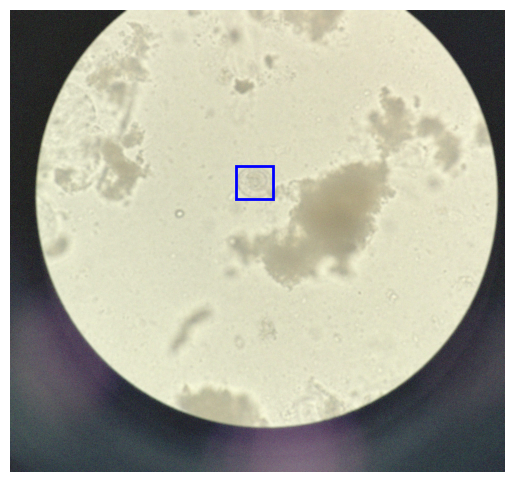

In [153]:
def show_with_box(row: pd.Series):
    img = Image.open(row['path'])
    x, y, w, h = row['bbox']

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(img)
    ax.add_patch(patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='blue', facecolor='none'))
    ax.axis('off')
    plt.show()

show_with_box(train_df.iloc[324])

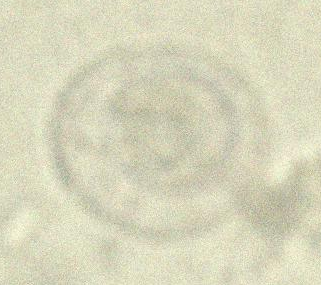

In [157]:
def crop_egg(row: pd.Series, margin: float = 0.2):
    img = Image.open(row['path'])
    x, y, w, h = row['bbox']

    # add some space around the egg (20% of the box size)
    mx, my = w * margin, h * margin
    left   = max(0, x - mx)
    top    = max(0, y - my)
    right  = min(img.width,  x + w + mx)
    bottom = min(img.height, y + h + my)

    return img.crop((left, top, right, bottom))

crop_egg(train_df.iloc[324])

### This code is how we get all image_ids that contain 2 or more eggs in one image.

  **`multiple_eggs = images_with_annotations.value_counts('image_id').sort_values(ascending=False).head(30)`**

In [114]:
multiple_eggs = train_images_with_annotations.value_counts('image_id').sort_values(ascending=False).head(30)
multiple_eggs

image_id
9057     3
9208     3
9283     2
10953    2
10857    2
10843    2
10705    2
10206    2
10189    2
10090    2
10056    2
10038    2
9978     2
9869     2
9292     2
10240    2
9158     2
1217     2
680      2
9141     2
1060     2
1208     2
1209     2
1099     2
1218     2
1256     2
1848     2
1988     2
9009     2
7319     1
Name: count, dtype: int64